# Naming that depends on population

In 10 every touched unit is named with one probability, and the event's own unit is always named. In the real record a unit is named when something happened there that someone wrote down, so a flood over forest goes unnamed and one over a district town does not. Here each touched unit is named with a probability that rises with its population, the event's own unit included, and an event enters the record only if it names at least one unit, so the record thins events where few people live. Population is partly tied to the river, as it is in reality, so where people live and where hazard is high overlap. The record is fitted four ways: 09's event likelihood, 10's footprint model with one naming probability, a footprint model whose naming probability is a logistic function of each unit's population, and the event likelihood with the same population-dependent detection but no footprint.

In [1]:
import arviz as az
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import shapely

from scipy import sparse
from scipy.special import expit
from scipy.stats import norm
from tqdm.auto import tqdm

from nested_plotting import POSTERIOR_COLOR, TRUTH_COLOR, plot_atoms

from climate_risk.models.aggregation import Aggregation
from climate_risk.plotting import configure_plot_style

configure_plot_style()

# One generator per stage, so rerunning a stage never moves the draws of another. The first seven match 10.
SEED = 20261020
GEOGRAPHY_SEED, COLOR_SEED, FIELD_SEED, EVENT_SEED, REPORTING_SEED, OFFSET_SEED, FOOTPRINT_SEED, POPULATION_SEED = (SEED + step for step in range(8))

## The geography and the hazard

As in 07 to 10: a 30 by 30 lattice of atoms grouped into 60 ADM2, 12 ADM1 and 3 ADM0 units, and a log rate of event centers linear in distance to a river and elevation, plus a Matern 3/2 field and nested unit offsets. Its level is set further down, once detection is known, so that the expected number of recorded events matches the median country's 25.

In [2]:
GRID_SIDE = 30
N_ADM2, N_ADM1, N_ADM0 = 60, 12, 3
LLOYD_STEPS = 25
LEVELS = ("ADM2", "ADM1", "ADM0")

n_atoms = GRID_SIDE**2
column, row = (index.ravel() for index in np.meshgrid(np.arange(GRID_SIDE), np.arange(GRID_SIDE)))
atom_x, atom_y = (column + 0.5) / GRID_SIDE, (row + 0.5) / GRID_SIDE
atom_centroids = np.column_stack([atom_x, atom_y])

# Edges as k / GRID_SIDE, computed once per grid line, so neighbors share them exactly and a
# dissolve leaves no slivers between atoms.
edges = np.arange(GRID_SIDE + 1) / GRID_SIDE
atom_cells = gpd.GeoSeries(shapely.box(edges[column], edges[row], edges[column + 1], edges[row + 1]))

In [3]:
def group_into(centroids, n_groups, *, weights, rng):
    """Assign each child to one of ``n_groups`` compact parents, by weighted Lloyd iteration."""
    seeds = centroids[rng.choice(len(centroids), size=n_groups, replace=False)]
    for _ in range(LLOYD_STEPS):
        parent = np.argmin(((centroids[:, None, :] - seeds[None, :, :]) ** 2).sum(axis=-1), axis=1)
        seeds = np.array(
            [np.average(centroids[parent == group], axis=0, weights=weights[parent == group]) for group in range(n_groups)]
        )

    return parent, seeds


geography_rng = np.random.default_rng(GEOGRAPHY_SEED)
adm2_of_atom, adm2_centroids = group_into(atom_centroids,
                                          N_ADM2,
                                          weights=np.ones(n_atoms),
                                          rng=geography_rng)
adm1_of_adm2, adm1_centroids = group_into(adm2_centroids,
                                          N_ADM1,
                                          weights=np.bincount(adm2_of_atom),
                                          rng=geography_rng)
adm0_of_adm1, _ = group_into(adm1_centroids,
                             N_ADM0,
                             weights=np.bincount(adm1_of_adm2[adm2_of_atom]),
                             rng=geography_rng)

unit_of_atom = {
    "ADM2": adm2_of_atom,
    "ADM1": adm1_of_adm2[adm2_of_atom],
    "ADM0": adm0_of_adm1[adm1_of_adm2[adm2_of_atom]],
}
borders = {
    level: gpd.GeoDataFrame({"unit": unit_of_atom[level]}, geometry=atom_cells).dissolve(by="unit").boundary
    for level in LEVELS
}
n_units = {level: int(unit_of_atom[level].max()) + 1 for level in LEVELS}
# Every unit of every level in one index: ADM2 first, then ADM1, then ADM0.
unit_offset = dict(zip(LEVELS, np.cumsum([0, *(n_units[level] for level in LEVELS[:-1])]), strict=True))
n_all_units = sum(n_units.values())

In [4]:
# Calibrated against EM-DAT in 07: the median country's recorded climate-related events from 1990 to 2023, and the
# share of events at each finest reporting level.
REAL_EVENTS_PER_COUNTRY = 25.0
REAL_LEVEL_SHARES = {"ADM2": 0.43, "ADM1": 0.44, "ADM0": 0.12}

TARGET_EVENTS = round(N_ADM0 * REAL_EVENTS_PER_COUNTRY)
TRUE_SLOPES = np.array([-0.8, 0.5])
COVARIATE_NAMES = ("distance to river", "elevation")
TRUE_FIELD_AMPLITUDE = 0.7
TRUE_FIELD_LENGTHSCALE = 0.12
TRUE_OFFSET_SDS = {"ADM2": 0.3, "ADM1": 0.4, "ADM0": 0.5}
FIELD_JITTER = 1e-8


def standardized(values):
    """Centered and scaled to unit standard deviation."""
    return (values - values.mean()) / values.std()


def matern32(points, *, amplitude, lengthscale):
    """The Matern 3/2 covariance between every pair of ``points``."""
    scaled = np.sqrt(3.0) * np.sqrt(((points[:, None, :] - points[None, :, :]) ** 2).sum(axis=-1)) / lengthscale

    return amplitude**2 * (1.0 + scaled) * np.exp(-scaled)


def gaussian_field(rng, *, amplitude, lengthscale):
    """One draw of a centered Matern 3/2 field over the atoms."""
    covariance = matern32(atom_centroids, amplitude=amplitude, lengthscale=lengthscale)
    covariance[np.diag_indices(n_atoms)] += FIELD_JITTER
    field = np.linalg.cholesky(covariance) @ rng.standard_normal(n_atoms)

    return field - field.mean()


river_x = 0.5 + 0.2 * np.sin(2.5 * np.pi * atom_y)
elevation = np.sin(3.0 * atom_x + 1.0) * np.cos(2.0 * atom_y) + 0.6 * atom_y
covariates = np.column_stack([standardized(np.abs(atom_x - river_x)), standardized(elevation)])

true_field = gaussian_field(np.random.default_rng(FIELD_SEED), amplitude=TRUE_FIELD_AMPLITUDE, lengthscale=TRUE_FIELD_LENGTHSCALE)

offset_rng = np.random.default_rng(OFFSET_SEED)
true_offsets = {level: offset_rng.normal(loc=0.0, scale=TRUE_OFFSET_SDS[level], size=n_units[level]) for level in LEVELS}
offset_part = sum(true_offsets[level][unit_of_atom[level]] for level in LEVELS)

# The log rate up to its intercept, which is set once detection is known.
log_rate_shape = covariates @ TRUE_SLOPES + true_field + offset_part

## Population and naming

Log population is a Matern 3/2 field with a lengthscale of 0.08, pulled toward the river with a loading of 0.8 on standardized distance, scaled to a spread of 1.5 in the log. A unit's population is the sum over its atoms. A touched unit is named with probability $\text{logit}^{-1}(a + b\, z_u)$, where $z_u$ is the unit's log population standardized across the units of its level, with $a = 0.8$ and $b = 1.2$. Log population correlates with distance to the river at -0.70, and ADM2 naming probabilities run from 0.10 to 0.95 with a median of 0.68, highest in the dense band north and west of the river.

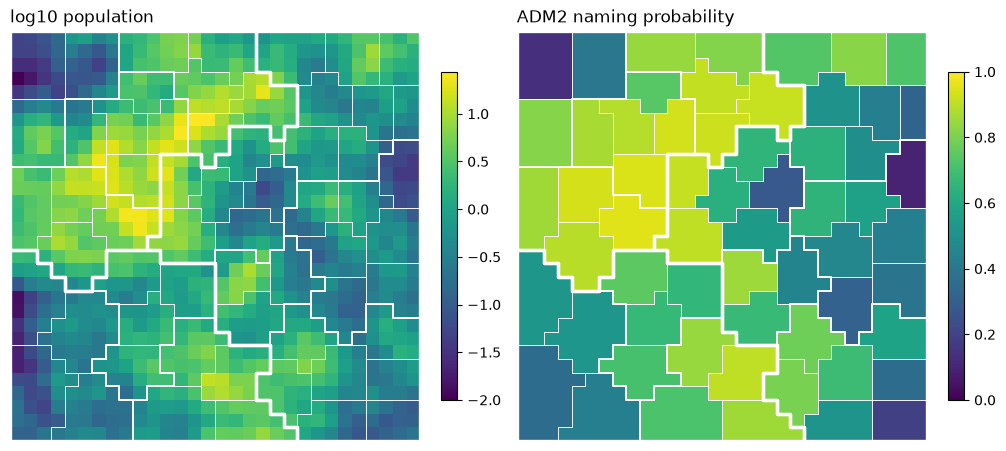

correlation of log population with distance to river   -0.70
ADM2 naming probability, min                            0.10
ADM2 naming probability, median                         0.68
ADM2 naming probability, max                            0.95
dtype: float64

In [5]:
POPULATION_LENGTHSCALE = 0.08
POPULATION_RIVER_LOADING = 0.8
POPULATION_LOG_SPREAD = 1.5
TRUE_NAMING_INTERCEPT = 0.8
TRUE_NAMING_SLOPE = 1.2

population_field = gaussian_field(np.random.default_rng(POPULATION_SEED), amplitude=1.0, lengthscale=POPULATION_LENGTHSCALE)
log_population = POPULATION_LOG_SPREAD * standardized(population_field - POPULATION_RIVER_LOADING * covariates[:, 0])
population = np.exp(log_population)

# Each unit's log population, standardized across the units of its level, in the all-units index.
population_z = np.concatenate([standardized(np.log(np.bincount(unit_of_atom[level], weights=population))) for level in LEVELS])
true_naming = expit(TRUE_NAMING_INTERCEPT + TRUE_NAMING_SLOPE * population_z)

figure, axes = plt.subplots(1, 2, figsize=(10, 4.4))
drawn = plot_atoms(axes[0],
                   log_population / np.log(10),
                   borders,
                   title="log10 population",
                   cmap="viridis")
figure.colorbar(drawn, ax=axes[0], shrink=0.8)
drawn = plot_atoms(axes[1],
                   true_naming[unit_offset["ADM2"] + unit_of_atom["ADM2"]],
                   borders,
                   title="ADM2 naming probability",
                   cmap="viridis",
                   vmin=0.0,
                   vmax=1.0)
figure.colorbar(drawn, ax=axes[1], shrink=0.8)
plt.show()

pd.Series({
    "correlation of log population with distance to river": np.corrcoef(log_population, covariates[:, 0])[0, 1],
    "ADM2 naming probability, min": true_naming[:N_ADM2].min(),
    "ADM2 naming probability, median": np.median(true_naming[:N_ADM2]),
    "ADM2 naming probability, max": true_naming[:N_ADM2].max(),
}).round(2)

## Footprints, detection and the record

The footprint is 10's: an ellipse with a log-normal equal-area radius calibrated to the share of its country a real hydrometeorological event names, aspects 1, 0.5 and 0.25 and a uniform angle. Each event is reported at a level drawn from the real record's shares, and each unit its footprint touches at that level is named with that unit's naming probability. An event that names no unit is not recorded. The rate's intercept is set so that the expected number of recorded events is 75, using the probability of recording an event centered at each atom, computed on the model's grid of shapes at the true footprint distribution.

In [6]:
# Hydrometeorological events reported at ADM2 in 08: the share of the country's GADM ADM2 units named, by quantile.
REAL_SHARE_OF_COUNTRY = {0.5: 0.008, 0.75: 0.027, 0.9: 0.0768, 0.99: 0.4624}
LARGEST_RADIUS = 1.0
ASPECTS = (1.0, 0.5, 0.25)
TRUE_ASPECT_WEIGHTS = np.array([0.4, 0.4, 0.2])
GRID_RADII = np.geomspace(0.02, LARGEST_RADIUS, 10)
GRID_ANGLES = np.arange(4) * np.pi / 4
# Interior bin edges halfway between neighboring radii in the log; the outer bins take the tails.
LOG_RADIUS_EDGES = (np.log(GRID_RADII[:-1]) + np.log(GRID_RADII[1:])) / 2

country_area = np.bincount(unit_of_atom["ADM0"]).mean() / n_atoms
quantiles = np.array(list(REAL_SHARE_OF_COUNTRY))
radius_at_quantile = np.sqrt(np.array(list(REAL_SHARE_OF_COUNTRY.values())) * country_area / np.pi)
TRUE_RADIUS_SPREAD, log_median = np.polyfit(norm.ppf(quantiles), np.log(radius_at_quantile), deg=1)
TRUE_MEDIAN_RADIUS = float(np.exp(log_median))

# Offsets from every atom (rows) to every other atom (columns).
offset_x = atom_x[None, :] - atom_x[:, None]
offset_y = atom_y[None, :] - atom_y[:, None]


def inside_ellipse(dx, dy, radius, aspect, angle):
    """Whether offsets ``dx`` and ``dy`` from a center lie inside the ellipse of equal-area ``radius``."""
    along = dx * np.cos(angle) + dy * np.sin(angle)
    across = -dx * np.sin(angle) + dy * np.cos(angle)

    return (along * np.sqrt(aspect) / radius) ** 2 + (across / (radius * np.sqrt(aspect))) ** 2 <= 1.0


shapes = pd.DataFrame(
    [{"radius_index": radius_index, "aspect_index": aspect_index, "angle": angle, "angles_at_aspect": 1 if aspect == 1.0 else len(GRID_ANGLES)}
     for radius_index in range(len(GRID_RADII))
     for aspect_index, aspect in enumerate(ASPECTS)
     for angle in ([0.0] if aspect == 1.0 else GRID_ANGLES)]
)
shape_coverage = np.stack([
    inside_ellipse(offset_x, offset_y, GRID_RADII[shape.radius_index], ASPECTS[shape.aspect_index], shape.angle)
    for shape in shapes.itertuples()
])
# Which units at each level the shape centered at each atom touches, shape (shape, center, unit).
touched_by_shape = {
    level: shape_coverage.astype(np.float32) @ np.eye(n_units[level], dtype=np.float32)[unit_of_atom[level]] > 0
    for level in LEVELS
}


def radius_mass_numpy(median_radius, radius_spread):
    """The log-normal radius distribution's probability in each grid radius's bin."""
    return np.diff(np.concatenate([[0.0], norm.cdf((LOG_RADIUS_EDGES - np.log(median_radius)) / radius_spread), [1.0]]))


true_shape_weights = (radius_mass_numpy(TRUE_MEDIAN_RADIUS, TRUE_RADIUS_SPREAD)[shapes["radius_index"]]
                      * TRUE_ASPECT_WEIGHTS[shapes["aspect_index"]]
                      / shapes["angles_at_aspect"]).to_numpy()

pd.Series({"median radius": TRUE_MEDIAN_RADIUS, "radius spread": TRUE_RADIUS_SPREAD, "grid shapes": len(shapes)}).round(3)

median radius    0.03
radius spread    0.87
grid shapes     90.00
dtype: float64

In [7]:
LEVEL_SHARES = np.array([REAL_LEVEL_SHARES[level] for level in LEVELS]) / sum(REAL_LEVEL_SHARES.values())


def detection_probability(level, naming):
    """The probability that each grid shape centered at each atom names at least one unit at ``level``, shape (shape, center)."""
    log_all_missed = touched_by_shape[level].astype(float) @ np.log1p(-naming[unit_offset[level]:unit_offset[level] + n_units[level]])

    return 1.0 - np.exp(log_all_missed)


true_detection = sum(share * true_shape_weights @ detection_probability(level, true_naming) for level, share in zip(LEVELS, LEVEL_SHARES))
TRUE_INTERCEPT = float(np.log(TARGET_EVENTS / (np.exp(log_rate_shape) * true_detection).sum()))
true_log_rate = TRUE_INTERCEPT + log_rate_shape
true_rate = np.exp(true_log_rate)


def name_units(center, inside, level, rng):
    """The units at ``level`` an event names: each unit its footprint touches, with that unit's naming probability."""
    touched = np.unique(unit_of_atom[level][inside])

    return touched[rng.random(len(touched)) < true_naming[unit_offset[level] + touched]]


event_rng = np.random.default_rng(EVENT_SEED)
footprint_rng = np.random.default_rng(FOOTPRINT_SEED + 1)
reporting_rng = np.random.default_rng(REPORTING_SEED)

centers = np.repeat(np.arange(n_atoms), event_rng.poisson(true_rate))
radii = np.minimum(TRUE_MEDIAN_RADIUS * np.exp(TRUE_RADIUS_SPREAD * footprint_rng.standard_normal(len(centers))), LARGEST_RADIUS)
aspects = footprint_rng.choice(ASPECTS, size=len(centers), p=TRUE_ASPECT_WEIGHTS)
angles = footprint_rng.uniform(0.0, np.pi, size=len(centers))
insides = [inside_ellipse(offset_x[center], offset_y[center], radius, aspect, angle)
           for center, radius, aspect, angle in zip(centers, radii, aspects, angles)]
levels = reporting_rng.choice(LEVELS, size=len(centers), p=LEVEL_SHARES)
named = [name_units(center, inside, level, reporting_rng) for center, inside, level in zip(centers, insides, levels)]
recorded = np.array([len(units) > 0 for units in named])

record = {
    "centers": centers[recorded],
    "insides": [inside for inside, kept in zip(insides, recorded) if kept],
    "levels": levels[recorded],
    "named": [units for units, kept in zip(named, recorded) if kept],
    "units named": np.array([len(units) for units in named])[recorded],
}

pd.Series({
    "expected event centers": true_rate.sum(),
    "event centers drawn": len(centers),
    "events recorded": int(recorded.sum()),
    "share recorded": recorded.mean(),
    **{f"recorded at {level}": int((record["levels"] == level).sum()) for level in LEVELS},
    "units named per recorded event, mean": record["units named"].mean(),
    "recorded events naming one unit": (record["units named"] == 1).mean(),
}).round(2)

expected event centers                 101.85
event centers drawn                    124.00
events recorded                         78.00
share recorded                           0.63
recorded at ADM2                        36.00
recorded at ADM1                        33.00
recorded at ADM0                         9.00
units named per recorded event, mean     1.60
recorded events naming one unit          0.69
dtype: float64

The draw put 124 event centers on the map against 102 expected, and 63% of them are recorded: 78 events, 36 at ADM2, 33 at ADM1 and 9 at ADM0. Recorded events name 1.6 units on average, and 69% name one.

## Three likelihoods

The event likelihood and the fixed footprint model are 10's. The population model drops the rule that an event names its own unit. A record that names the set $S$ at level $L$ comes from any center $c$ and shape $k$ whose footprint $T_{ck}$ touches all of $S$, wherever the center lies, with probability
$$p_L\, \lambda_c\, w_k \prod_{u \in S} q_u \prod_{u \in T_{ck} \setminus S} (1 - q_u), \qquad \text{logit}\, q_u = a + b\, z_u,$$
with Dirichlet(1, 1, 1) level probabilities $p_L$. Only events that name a unit are recorded, so the expected number of recorded events is
$$\Lambda_{\text{rec}} = \sum_L p_L \sum_{c, k} \lambda_c\, w_k \Big[1 - \prod_{u \in T_{ck}} (1 - q_u)\Big].$$
Since $S$ lies inside $T_{ck}$, the product over missed units is the product over all of $T_{ck}$ divided by the product over $S$. The first depends only on the center and shape and is the same quantity the recorded total needs, computed once for every one of the 81,000 pairs at each level, and the second is a constant of the record. Each record's sum is then a sparse mask over that dense array, which is exact and needs no grouping by missed units.

In [8]:
def distinct_records(record):
    """Each distinct (level, named set), how many events share it, and the record index of every event."""
    record_index = {}
    record_of_event = np.array([record_index.setdefault((level, tuple(np.sort(named))), len(record_index))
                                for level, named in zip(record["levels"], record["named"], strict=True)])

    return list(record_index), np.bincount(record_of_event), record_of_event


def union_operator(record):
    """One row per event over the atoms of the units it names, for the event likelihood."""
    union_atoms = [np.flatnonzero(np.isin(unit_of_atom[level], named)) for level, named in zip(record["levels"], record["named"], strict=True)]

    return Aggregation(units=tuple(f"event {event}" for event in range(len(union_atoms))),
                       rows=np.repeat(np.arange(len(union_atoms)), [len(atoms) for atoms in union_atoms]),
                       columns=np.concatenate(union_atoms),
                       weights=np.ones(sum(len(atoms) for atoms in union_atoms)),
                       n_cells=n_atoms)


def fixed_naming_terms(record):
    """10's grouped terms: centers inside the named units, grouped by record, center and count of units missed."""
    distinct, multiplicity, _ = distinct_records(record)
    term_record, term_center, term_missed, pair_term, pair_shape = [], [], [], [], []
    for index, (level, named) in enumerate(distinct):
        named = np.array(named)
        candidates = np.flatnonzero(np.isin(unit_of_atom[level], named))
        touched = touched_by_shape[level][:, candidates, :]
        shape_index, candidate_index = np.nonzero(touched[:, :, named].all(axis=-1))
        missed = touched.sum(axis=-1)[shape_index, candidate_index] - len(named)
        keys, inverse = np.unique(np.column_stack([candidates[candidate_index], missed]), axis=0, return_inverse=True)

        pair_term.append(sum(len(centers) for centers in term_center) + inverse.ravel())
        pair_shape.append(shape_index)
        term_record.append(np.full(len(keys), index))
        term_center.append(keys[:, 0])
        term_missed.append(keys[:, 1])

    n_terms = sum(len(centers) for centers in term_center)
    return {
        "multiplicity": multiplicity,
        "named": np.array([len(named) for _, named in distinct]),
        "center": np.concatenate(term_center),
        "missed": np.concatenate(term_missed),
        "shape mass": Aggregation(units=tuple(f"term {term}" for term in range(n_terms)),
                                  rows=np.concatenate(pair_term),
                                  columns=np.concatenate(pair_shape),
                                  weights=np.ones(sum(len(shapes_) for shapes_ in pair_shape)),
                                  n_cells=len(shapes)),
        "by record": Aggregation(units=tuple(f"record {index}" for index in range(len(distinct))),
                                 rows=np.concatenate(term_record),
                                 columns=np.arange(n_terms),
                                 weights=np.ones(n_terms),
                                 n_cells=n_terms),
    }


# Every (level, shape, center) in one flat index, level-major, so one sparse operator covers all three levels.
CELLS_PER_LEVEL = len(shapes) * n_atoms


def population_naming_terms(record):
    """For each distinct record, the (shape, center) cells whose footprint touches every named unit, and its named units."""
    distinct, multiplicity, _ = distinct_records(record)
    compatible_rows, compatible_cells, named_rows, named_units, record_level = [], [], [], [], []
    for index, (level, named) in enumerate(distinct):
        named = np.array(named)
        cells = np.flatnonzero(touched_by_shape[level][:, :, named].all(axis=-1).ravel())
        compatible_rows.append(np.full(len(cells), index))
        compatible_cells.append(LEVELS.index(level) * CELLS_PER_LEVEL + cells)
        named_rows.append(np.full(len(named), index))
        named_units.append(unit_offset[level] + named)
        record_level.append(LEVELS.index(level))

    def operator(rows, columns, n_cells):
        return Aggregation(units=tuple(f"record {row}" for row in range(len(distinct))),
                           rows=np.concatenate(rows),
                           columns=np.concatenate(columns),
                           weights=np.ones(sum(len(row) for row in rows)),
                           n_cells=n_cells)

    return {
        "multiplicity": multiplicity,
        "level": np.array(record_level),
        "compatible": operator(compatible_rows, compatible_cells, len(LEVELS) * CELLS_PER_LEVEL),
        "named": operator(named_rows, named_units, n_all_units),
    }


fixed_terms = fixed_naming_terms(record)
population_terms = population_naming_terms(record)

pd.Series({
    "recorded events": int(population_terms["multiplicity"].sum()),
    "distinct records": len(population_terms["multiplicity"]),
    "fixed model terms": len(fixed_terms["center"]),
    "population model compatible cells": len(population_terms["compatible"].rows),
})

recorded events                           78
distinct records                          45
fixed model terms                      44989
population model compatible cells    1085075
dtype: int64

In [9]:
HSGP_BOUNDARY_FACTOR = 4.0
HSGP_BASIS_PER_AXIS = 50
OFFSET_SD_PRIOR = 0.5
sample_kwargs = {
    "chains": 8,
    "cores": 8,
    "tune": 500,
    "draws": 250,
    "target_accept": 0.9,
    "nuts_sampler": "nutpie",
    "random_seed": SEED,
}
COORDS = {
    "covariate": COVARIATE_NAMES,
    "atom": np.arange(n_atoms),
    "aspect": [f"{aspect:g}" for aspect in ASPECTS],
    "unit": np.arange(n_all_units),
    "level": list(LEVELS),
    **{level: np.arange(n_units[level]) for level in LEVELS},
}
# Which units a grid shape centered at each atom touches, flattened over (shape, center), per level.
touched_flat = {level: touched_by_shape[level].reshape(-1, n_units[level]).astype(float) for level in LEVELS}


def latent_log_rate():
    """The log rate of event centers at every atom under 07's prior, built inside the current model."""
    intercept = pm.Normal("intercept",
                          mu=0.0,
                          sigma=2.0)
    slopes = pm.Normal("slopes",
                       mu=0.0,
                       sigma=1.0,
                       dims="covariate")

    # Mode at 0.1 of the domain, about the side of an ADM2 unit, with a tail out past an ADM0.
    field_lengthscale = pm.InverseGamma("field_lengthscale",
                                        alpha=3.0,
                                        beta=0.4)
    field_amplitude = pm.HalfNormal("field_amplitude", sigma=1.0)
    gp = pm.gp.HSGP(m=[HSGP_BASIS_PER_AXIS, HSGP_BASIS_PER_AXIS],
                    c=HSGP_BOUNDARY_FACTOR,
                    cov_func=field_amplitude**2 * pm.gp.cov.Matern32(input_dim=2, ls=field_lengthscale))
    field = gp.prior("field", X=atom_centroids, dims="atom")

    # Summing every level's offsets at the atom nests them: an ADM2's total is its ADM1's plus its own deviation.
    offset_part = 0.0
    for level in LEVELS:
        offset_sd = pm.HalfNormal(f"{level}_offset_sd", sigma=OFFSET_SD_PRIOR)
        standard = pm.Normal(f"{level}_offset_standard",
                             mu=0.0,
                             sigma=1.0,
                             dims=level)
        offsets = pm.Deterministic(f"{level}_offset", offset_sd * standard, dims=level)
        offset_part = offset_part + offsets[unit_of_atom[level]]

    return pm.Deterministic("log_rate",
                            intercept + pm.math.dot(covariates, slopes) + field + offset_part,
                            dims="atom")


def footprint_shape_weights():
    """10's priors on the footprint, returned as each grid shape's probability."""
    log_median_radius = pm.Normal("log_median_radius",
                                  mu=np.log(0.1),
                                  sigma=1.0)
    radius_spread = pm.HalfNormal("radius_spread", sigma=1.0)
    aspect_weights = pm.Dirichlet("aspect_weights",
                                  a=np.ones(len(ASPECTS)),
                                  dims="aspect")
    below = 0.5 * (1.0 + pt.erf((LOG_RADIUS_EDGES - log_median_radius) / (radius_spread * np.sqrt(2.0))))
    radius_masses = pt.diff(pt.concatenate([pt.zeros(1), below, pt.ones(1)]))

    return pm.Deterministic("shape_weight",
                            radius_masses[shapes["radius_index"].to_numpy()]
                            * aspect_weights[shapes["aspect_index"].to_numpy()]
                            / shapes["angles_at_aspect"].to_numpy())


def located_logp(value, probability):
    """Log probability of one event's record, given its probability under the model."""
    return pt.log(probability)


def counted_logp(count, probability):
    """Log probability of ``count`` events sharing one record, given the record's probability under the model."""
    return count * pt.log(probability)


def build_event_model():
    """09's likelihood: a Poisson count of events, and each center somewhere in the units the event names."""
    unions = union_operator(record)

    with pm.Model(coords=COORDS | {"event": unions.units}) as model:
        rate = pm.math.exp(latent_log_rate())
        total_rate = rate.sum()
        pm.Poisson("event_count",
                   mu=total_rate,
                   observed=unions.n_units)
        pm.CustomDist("event_record",
                      unions.aggregate_symbolic(rate) / total_rate,
                      logp=located_logp,
                      observed=np.zeros(unions.n_units),
                      dims="event")

    return model


def build_fixed_naming_model():
    """10's footprint model: one naming probability, and every event names its own unit."""
    terms = fixed_terms

    with pm.Model(coords=COORDS | {"record": terms["by record"].units}) as model:
        rate = pm.math.exp(latent_log_rate())
        weights = footprint_shape_weights()
        naming_probability = pm.Beta("naming_probability",
                                     alpha=2.0,
                                     beta=2.0)

        term = rate[terms["center"]] * terms["shape mass"].aggregate_symbolic(weights) * (1.0 - naming_probability) ** terms["missed"]
        total_rate = rate.sum()
        pm.Poisson("event_count",
                   mu=total_rate,
                   observed=terms["multiplicity"].sum())
        pm.CustomDist("record_count",
                      terms["by record"].aggregate_symbolic(term) / total_rate * naming_probability ** (terms["named"] - 1),
                      logp=counted_logp,
                      observed=terms["multiplicity"],
                      dims="record")

    return model


def build_population_naming_model():
    """Each touched unit named with a probability set by its population, and only events naming a unit recorded."""
    terms = population_terms

    with pm.Model(coords=COORDS | {"record": terms["compatible"].units}) as model:
        rate = pm.math.exp(latent_log_rate())
        weights = footprint_shape_weights()
        naming_intercept = pm.Normal("naming_intercept",
                                     mu=0.0,
                                     sigma=1.5)
        naming_slope = pm.Normal("naming_slope",
                                 mu=0.0,
                                 sigma=1.0)
        naming = pm.Deterministic("naming_probability",
                                  pm.math.invlogit(naming_intercept + naming_slope * population_z),
                                  dims="unit")
        log_missed = pt.log1p(-naming)
        level_probability = pm.Dirichlet("level_probability",
                                         a=np.ones(len(LEVELS)),
                                         dims="level")

        # For every (shape, center): its rate times its shape's weight, times the chance it misses every unit it
        # touches. A record's sum divides out the named units, which every compatible footprint touches.
        cell_terms, recorded_rate = [], 0.0
        for index, level in enumerate(LEVELS):
            all_missed = pt.exp(pt.dot(touched_flat[level], log_missed[unit_offset[level]:unit_offset[level] + n_units[level]]))
            weighted = weights[:, None] * rate[None, :]
            cell_terms.append((weighted * all_missed.reshape((len(shapes), n_atoms))).ravel())
            recorded_rate = recorded_rate + level_probability[index] * (weighted * (1.0 - all_missed.reshape((len(shapes), n_atoms)))).sum()

        intensity = (level_probability[terms["level"]]
                     * terms["compatible"].aggregate_symbolic(pt.concatenate(cell_terms))
                     * pt.exp(terms["named"].aggregate_symbolic(pt.log(naming) - log_missed)))

        pm.Poisson("event_count",
                   mu=recorded_rate,
                   observed=terms["multiplicity"].sum())
        pm.CustomDist("record_count",
                      intensity / recorded_rate,
                      logp=counted_logp,
                      observed=terms["multiplicity"],
                      dims="record")

    return model


BUILDERS = {
    "event likelihood": build_event_model,
    "fixed naming": build_fixed_naming_model,
    "population naming": build_population_naming_model,
}

In [10]:
def direct_population_log_likelihood(rate, weights, naming, level_probability):
    """The population model's record term, event by event over every (center, shape), ungrouped."""
    log_q, log_missed = np.log(naming), np.log1p(-naming)
    recorded_rate = sum(level_probability[index] * weights @ detection_probability(level, naming) @ rate
                        for index, level in enumerate(LEVELS))

    total = 0.0
    for level, named in zip(record["levels"], record["named"], strict=True):
        level_units = slice(unit_offset[level], unit_offset[level] + n_units[level])
        touched = touched_by_shape[level]
        compatible = touched[:, :, named].all(axis=-1)
        missed_log = (touched & ~np.isin(np.arange(n_units[level]), named)) @ log_missed[level_units]
        probability = (weights[:, None] * rate[None, :] * np.exp(missed_log) * compatible).sum()
        total += np.log(level_probability[LEVELS.index(level)] * probability * np.exp(log_q[unit_offset[level] + named].sum()) / recorded_rate)

    return total


check_model = build_population_naming_model()
point = check_model.initial_point(random_seed=SEED)
outputs = [check_model["log_rate"], check_model["shape_weight"], check_model["naming_probability"], check_model["level_probability"]]
log_rate, weights, naming, level_probability = check_model.compile_fn(check_model.replace_rvs_by_values(outputs),
                                                                      inputs=check_model.value_vars,
                                                                      on_unused_input="ignore")(point)

pd.Series({
    "direct": direct_population_log_likelihood(np.exp(log_rate), weights, naming, level_probability),
    "grouped": float(check_model.compile_logp(vars=[check_model["record_count"]])(point)),
})

direct    -461.48
grouped   -461.48
dtype: float64

### Detection without a footprint

The event likelihood with a detection term and no footprint. An event centered at atom $c$ and reported at level $L$ is recorded with the naming probability of its own unit at that level, $q_{u_L(c)} = \text{logit}^{-1}(a + b\, z_{u_L(c)})$, and a recorded event's center lies somewhere in the units it names:
$$P(\text{record } e) \propto p_L \sum_{c \in U_e} \lambda_c\, q_{u_L(c)}, \qquad \Lambda_{\text{rec}} = \sum_L p_L \sum_c \lambda_c\, q_{u_L(c)}.$$
The truth records an event if any unit its footprint touches is named, so this is an approximation that holds when most footprints touch one unit, as most do here.

In [11]:
# Each (level, atom) in one flat index, level-major, and the all-units index of the atom's unit at that level.
center_unit = np.concatenate([unit_offset[level] + unit_of_atom[level] for level in LEVELS])


def detection_union_terms(record):
    """For each distinct record, the (level, atom) cells of the units it names, and how many events share it."""
    distinct, multiplicity, _ = distinct_records(record)
    rows, columns = [], []
    for index, (level, named) in enumerate(distinct):
        atoms = np.flatnonzero(np.isin(unit_of_atom[level], named))
        rows.append(np.full(len(atoms), index))
        columns.append(LEVELS.index(level) * n_atoms + atoms)

    return {
        "multiplicity": multiplicity,
        "level": np.array([LEVELS.index(level) for level, _ in distinct]),
        "union": Aggregation(units=tuple(f"record {index}" for index in range(len(distinct))),
                             rows=np.concatenate(rows),
                             columns=np.concatenate(columns),
                             weights=np.ones(sum(len(row) for row in rows)),
                             n_cells=len(LEVELS) * n_atoms),
    }


detection_terms = detection_union_terms(record)


def build_event_detection_model():
    """The event likelihood with each event recorded with the naming probability of its center's unit."""
    terms = detection_terms

    with pm.Model(coords=COORDS | {"record": terms["union"].units}) as model:
        rate = pm.math.exp(latent_log_rate())
        naming_intercept = pm.Normal("naming_intercept",
                                     mu=0.0,
                                     sigma=1.5)
        naming_slope = pm.Normal("naming_slope",
                                 mu=0.0,
                                 sigma=1.0)
        naming = pm.Deterministic("naming_probability",
                                  pm.math.invlogit(naming_intercept + naming_slope * population_z),
                                  dims="unit")
        level_probability = pm.Dirichlet("level_probability",
                                         a=np.ones(len(LEVELS)),
                                         dims="level")

        detected_rate = pt.tile(rate, len(LEVELS)) * naming[center_unit]
        recorded_rate = (level_probability * detected_rate.reshape((len(LEVELS), n_atoms)).sum(axis=1)).sum()
        intensity = level_probability[terms["level"]] * terms["union"].aggregate_symbolic(detected_rate)

        pm.Poisson("event_count",
                   mu=recorded_rate,
                   observed=terms["multiplicity"].sum())
        pm.CustomDist("record_count",
                      intensity / recorded_rate,
                      logp=counted_logp,
                      observed=terms["multiplicity"],
                      dims="record")

    return model


BUILDERS["event likelihood, detection"] = build_event_detection_model

In [12]:
fits = {}
for model_name, build in BUILDERS.items():
    with build():
        fits[model_name] = pm.sample(**sample_kwargs)

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard, log_median_radius, radius_spread, aspect_weights, naming_probability]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard, log_median_radius, radius_spread, aspect_weights, naming_intercept, naming_slope, level_probability]


Output()

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, ADM0_offset_sd, ADM0_offset_standard, naming_intercept, naming_slope, level_probability]


Output()

## What each likelihood recovers

Against the true rate of event centers, recorded or not, and the true hit rate, the rate a footprint covers each atom, which averages 2,000 footprints from the true distribution. The event likelihood and the fixed model treat every event as recorded, so their totals estimate recorded events, not all events.

In [13]:
INTERVAL = 0.9
INTERVAL_BOUNDS = ((1 - INTERVAL) / 2, (1 + INTERVAL) / 2)
TRUE_HIT_DRAWS = 2_000
HIT_RATE_DRAWS = 50

truth_rng = np.random.default_rng(FOOTPRINT_SEED + 2)
true_cover = np.zeros((n_atoms, n_atoms))
for radius, aspect, angle in zip(np.minimum(TRUE_MEDIAN_RADIUS * np.exp(TRUE_RADIUS_SPREAD * truth_rng.standard_normal(TRUE_HIT_DRAWS)), LARGEST_RADIUS),
                                 truth_rng.choice(ASPECTS, size=TRUE_HIT_DRAWS, p=TRUE_ASPECT_WEIGHTS),
                                 truth_rng.uniform(0.0, np.pi, size=TRUE_HIT_DRAWS)):
    true_cover += inside_ellipse(offset_x, offset_y, radius, aspect, angle)
true_hit_rate = true_rate @ (true_cover / TRUE_HIT_DRAWS)


def correlation(left, right):
    """Pearson correlation of two arrays."""
    return float(np.corrcoef(left, right)[0, 1])


def hit_rate_draws(idata):
    """The hit rate at every atom for HIT_RATE_DRAWS posterior draws, shape (draw, atom)."""
    posterior = az.extract(idata, num_samples=HIT_RATE_DRAWS, random_seed=SEED)
    rate = np.exp(posterior["log_rate"].to_numpy())
    weights = posterior["shape_weight"].to_numpy()

    return np.stack([rate[:, draw] @ np.tensordot(weights[:, draw], shape_coverage, axes=1) for draw in range(HIT_RATE_DRAWS)])


def fit_summary(idata):
    """How one fit's center rate, slopes and field compare with the truth, and its hit rate where it has one."""
    posterior = idata.posterior
    log_rate = posterior["log_rate"].mean(dim=("chain", "draw")).to_numpy()
    lower, upper = posterior["log_rate"].quantile(INTERVAL_BOUNDS, dim=("chain", "draw")).to_numpy()
    slopes = posterior["slopes"].mean(dim=("chain", "draw")).to_numpy()

    summary = {
        "total center rate / true": float(np.exp(posterior["log_rate"]).sum("atom").mean() / true_rate.sum()),
        "log rate, correlation with center rate": correlation(log_rate, true_log_rate),
        f"center log rate, {INTERVAL:.0%} coverage": float(((true_log_rate >= lower) & (true_log_rate <= upper)).mean()),
        "field, correlation with truth": correlation(posterior["field"].mean(dim=("chain", "draw")).to_numpy(), true_field),
        **{f"slope on {name}": float(slope) for name, slope in zip(COVARIATE_NAMES, slopes, strict=True)},
        "divergences": int(idata.sample_stats["diverging"].sum()),
        "sampling seconds": float(posterior.attrs["sampling_time"]),
    }
    if "shape_weight" not in posterior:
        return summary

    hit_rate = hit_rate_draws(idata).mean(axis=0)
    return summary | {
        "log hit rate, correlation with true hit rate": correlation(np.log(hit_rate), np.log(true_hit_rate)),
        "hit rate total / true": float(hit_rate.sum() / true_hit_rate.sum()),
    }


pd.DataFrame(
    {"truth": {f"slope on {name}": slope for name, slope in zip(COVARIATE_NAMES, TRUE_SLOPES, strict=True)}}
    | {model_name: fit_summary(idata) for model_name, idata in fits.items()}
).round(2)

,truth,event likelihood,fixed naming,population naming,"event likelihood, detection"
slope on distance to river,-0.80,-1.00,-1.07,-0.79,-0.74
slope on elevation,0.50,1.06,0.99,0.97,1.07
total center rate / true,NaN,0.77,0.78,1.04,3.32
"log rate, correlation with center rate",NaN,0.85,0.84,0.87,0.86
"center log rate, 90% coverage",NaN,0.83,0.84,0.95,0.93
"field, correlation with truth",NaN,0.30,0.28,0.27,0.31
divergences,NaN,0.00,3.00,0.00,0.00
sampling seconds,NaN,19.51,90.91,557.76,21.45
"log hit rate, correlation with true hit rate",NaN,NaN,0.92,0.95,NaN
hit rate total / true,NaN,NaN,1.64,1.54,NaN


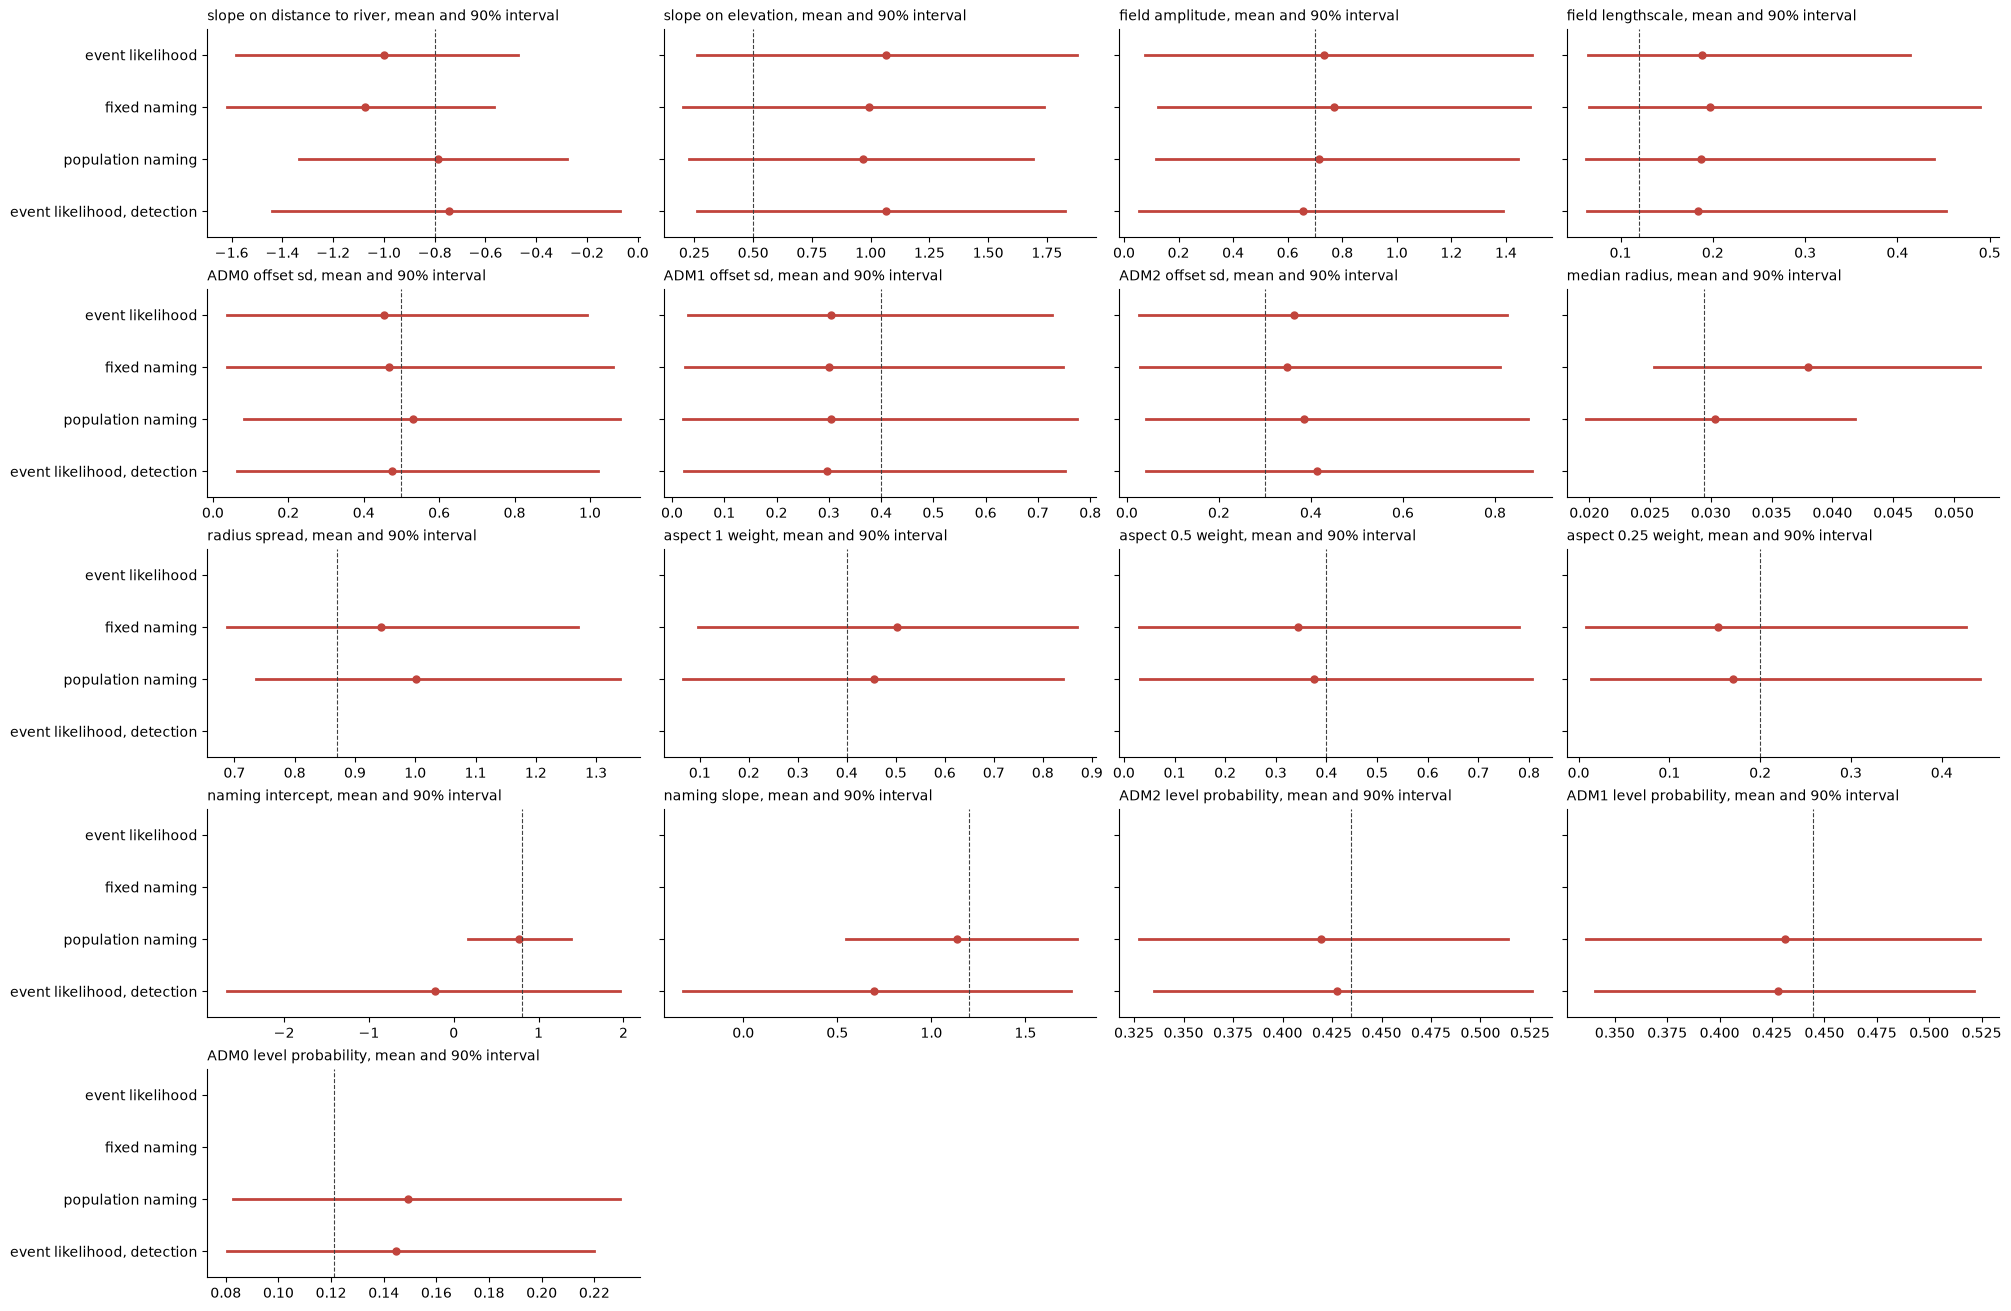

In [14]:
PANEL_COLUMNS = 4


def parameter_draws(posterior):
    """Draws of every parameter with a known true value that the fit has, keyed by name."""
    draws = {
        **{f"slope on {name}": posterior["slopes"].sel(covariate=name) for name in COVARIATE_NAMES},
        "field amplitude": posterior["field_amplitude"],
        "field lengthscale": posterior["field_lengthscale"],
        **{f"{level} offset sd": posterior[f"{level}_offset_sd"] for level in reversed(LEVELS)},
    }
    if "shape_weight" in posterior:
        draws |= {
            "median radius": np.exp(posterior["log_median_radius"]),
            "radius spread": posterior["radius_spread"],
            **{f"aspect {aspect} weight": posterior["aspect_weights"].sel(aspect=aspect) for aspect in COORDS["aspect"]},
        }
    if "naming_intercept" in posterior:
        draws |= {
            "naming intercept": posterior["naming_intercept"],
            "naming slope": posterior["naming_slope"],
            **{f"{level} level probability": posterior["level_probability"].sel(level=level) for level in LEVELS},
        }

    return draws


TRUE_PARAMETERS = {
    **{f"slope on {name}": slope for name, slope in zip(COVARIATE_NAMES, TRUE_SLOPES, strict=True)},
    "field amplitude": TRUE_FIELD_AMPLITUDE,
    "field lengthscale": TRUE_FIELD_LENGTHSCALE,
    **{f"{level} offset sd": TRUE_OFFSET_SDS[level] for level in reversed(LEVELS)},
    "median radius": TRUE_MEDIAN_RADIUS,
    "radius spread": TRUE_RADIUS_SPREAD,
    **{f"aspect {aspect} weight": weight for aspect, weight in zip(COORDS["aspect"], TRUE_ASPECT_WEIGHTS, strict=True)},
    "naming intercept": TRUE_NAMING_INTERCEPT,
    "naming slope": TRUE_NAMING_SLOPE,
    **{f"{level} level probability": share for level, share in zip(LEVELS, LEVEL_SHARES, strict=True)},
}
fit_draws = {model_name: parameter_draws(idata.posterior) for model_name, idata in fits.items()}

n_rows = -(-len(TRUE_PARAMETERS) // PANEL_COLUMNS)
figure, axes = plt.subplots(n_rows, PANEL_COLUMNS, figsize=(5.0 * PANEL_COLUMNS, 2.6 * n_rows), sharey=True)

for axis, (name, truth) in zip(axes.ravel(), TRUE_PARAMETERS.items()):
    for position, draws in enumerate(fit_draws.values()):
        if name not in draws:
            continue
        lower, upper = draws[name].quantile(INTERVAL_BOUNDS, dim=("chain", "draw")).to_numpy()
        axis.plot([lower, upper],
                  [position, position],
                  color=POSTERIOR_COLOR,
                  linewidth=2.0)
        axis.plot(float(draws[name].mean()),
                  position,
                  "o",
                  color=POSTERIOR_COLOR,
                  markersize=5)
    axis.axvline(truth,
                 color=TRUTH_COLOR,
                 linestyle="--",
                 linewidth=0.8)
    axis.set_title(f"{name}, mean and {INTERVAL:.0%} interval", loc="left", fontsize=10)

for axis in axes.ravel()[len(TRUE_PARAMETERS):]:
    axis.remove()
for row in axes:
    row[0].set_yticks(range(len(fit_draws)), list(fit_draws))
axes[0, 0].set_ylim(len(fit_draws) - 0.5, -0.5)
plt.show()

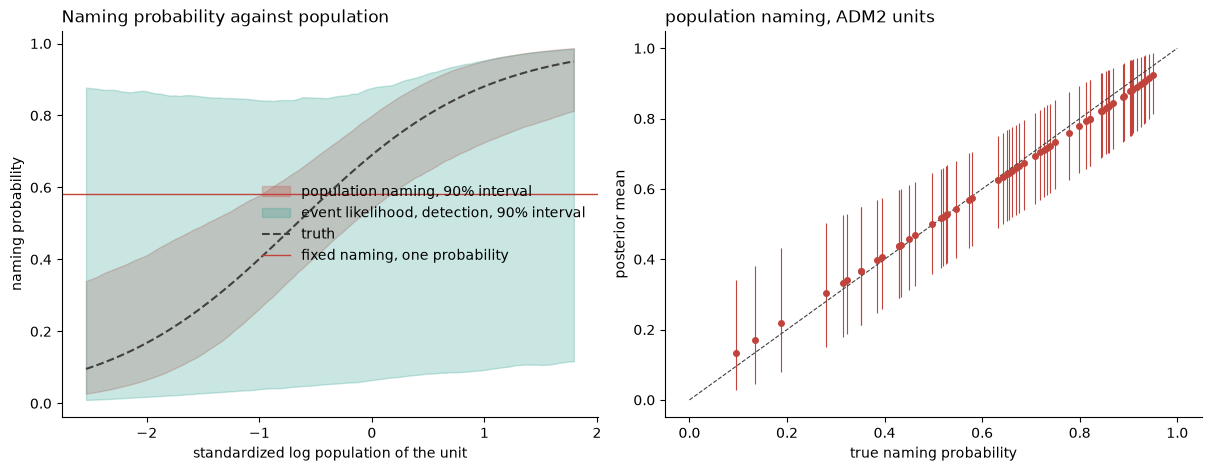

In [15]:
population_posterior = fits["population naming"].posterior
naming_mean = population_posterior["naming_probability"].mean(dim=("chain", "draw")).to_numpy()
naming_lower, naming_upper = population_posterior["naming_probability"].quantile(INTERVAL_BOUNDS, dim=("chain", "draw")).to_numpy()
adm2 = slice(unit_offset["ADM2"], unit_offset["ADM2"] + N_ADM2)
z_grid = np.linspace(population_z.min(), population_z.max(), 100)
NAMING_CURVE_COLORS = {"population naming": POSTERIOR_COLOR, "event likelihood, detection": "#2a9d8f"}

figure, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for model_name, color in NAMING_CURVE_COLORS.items():
    posterior = fits[model_name].posterior
    curve_draws = expit(posterior["naming_intercept"].to_numpy().ravel()[:, None]
                        + posterior["naming_slope"].to_numpy().ravel()[:, None] * z_grid[None, :])
    axes[0].fill_between(z_grid,
                         *np.quantile(curve_draws, INTERVAL_BOUNDS, axis=0),
                         color=color,
                         alpha=0.25,
                         label=f"{model_name}, {INTERVAL:.0%} interval")
axes[0].plot(z_grid,
             expit(TRUE_NAMING_INTERCEPT + TRUE_NAMING_SLOPE * z_grid),
             color=TRUTH_COLOR,
             linestyle="--",
             label="truth")
axes[0].axhline(float(fits["fixed naming"].posterior["naming_probability"].mean()),
                color=POSTERIOR_COLOR,
                linewidth=1.0,
                label="fixed naming, one probability")
axes[0].set_xlabel("standardized log population of the unit")
axes[0].set_ylabel("naming probability")
axes[0].set_title("Naming probability against population", loc="left")
axes[0].legend(frameon=False)

axes[1].errorbar(true_naming[adm2],
                 naming_mean[adm2],
                 yerr=[naming_mean[adm2] - naming_lower[adm2], naming_upper[adm2] - naming_mean[adm2]],
                 fmt="o",
                 markersize=4,
                 color=POSTERIOR_COLOR,
                 elinewidth=0.8)
axes[1].plot([0, 1],
             [0, 1],
             color=TRUTH_COLOR,
             linestyle="--",
             linewidth=0.8)
axes[1].set_xlabel("true naming probability")
axes[1].set_ylabel("posterior mean")
axes[1].set_title("population naming, ADM2 units", loc="left")
plt.show()

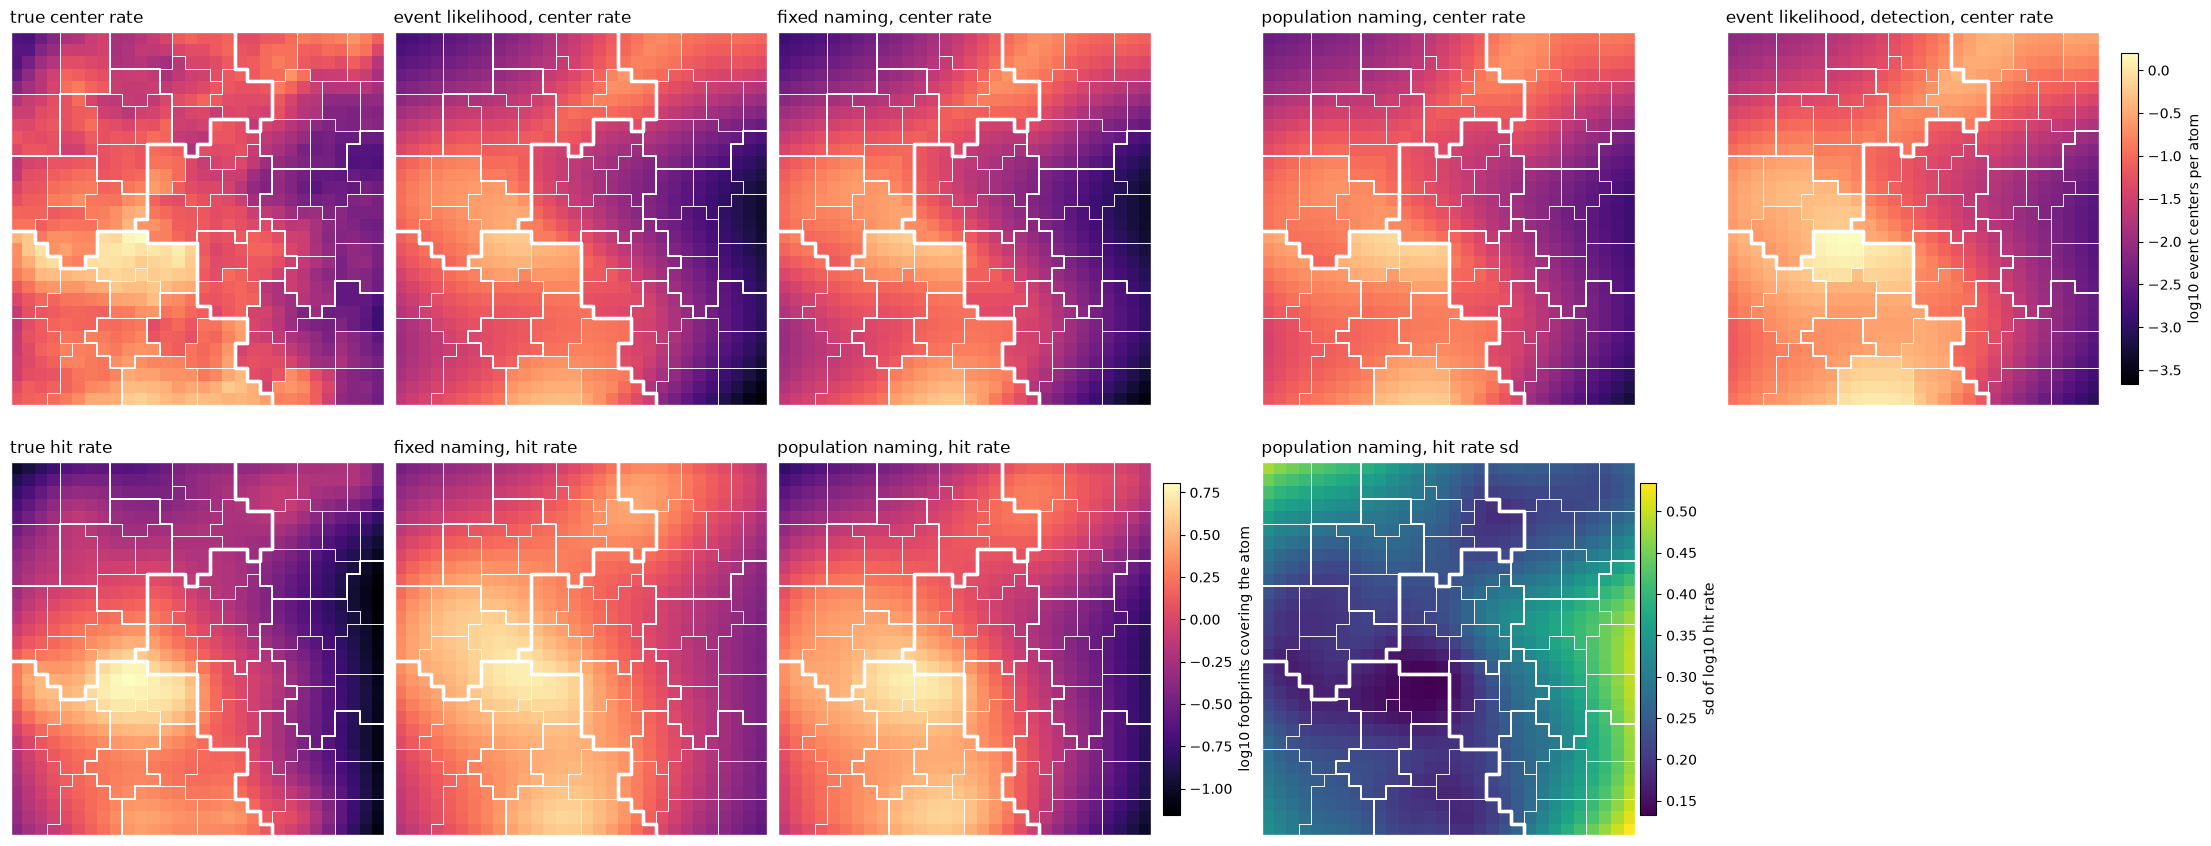

In [16]:
center_maps = {
    "true center rate": true_log_rate / np.log(10),
    **{f"{model_name}, center rate": idata.posterior["log_rate"].mean(dim=("chain", "draw")).to_numpy() / np.log(10)
       for model_name, idata in fits.items()},
}
population_hits = np.log10(hit_rate_draws(fits["population naming"]))
hit_maps = {
    "true hit rate": np.log10(true_hit_rate),
    "fixed naming, hit rate": np.log10(hit_rate_draws(fits["fixed naming"]).mean(axis=0)),
    "population naming, hit rate": population_hits.mean(axis=0),
}
center_limits = (min(values.min() for values in center_maps.values()), max(values.max() for values in center_maps.values()))
hit_limits = (min(values.min() for values in hit_maps.values()), max(values.max() for values in hit_maps.values()))

figure, axes = plt.subplots(2, len(center_maps), figsize=(4.4 * len(center_maps), 8.6))
for axis, (title, values) in zip(axes[0], center_maps.items(), strict=True):
    drawn = plot_atoms(axis,
                       values,
                       borders,
                       title=title,
                       vmin=center_limits[0],
                       vmax=center_limits[1])
figure.colorbar(drawn, ax=axes[0], shrink=0.8, pad=0.01, label="log10 event centers per atom")

for axis, (title, values) in zip(axes[1, :3], hit_maps.items(), strict=True):
    drawn = plot_atoms(axis,
                       values,
                       borders,
                       title=title,
                       vmin=hit_limits[0],
                       vmax=hit_limits[1])
figure.colorbar(drawn, ax=axes[1, :3], shrink=0.8, pad=0.01, label="log10 footprints covering the atom")

drawn = plot_atoms(axes[1, 3],
                   population_hits.std(axis=0),
                   borders,
                   title="population naming, hit rate sd",
                   cmap="viridis")
figure.colorbar(drawn, ax=axes[1, 3], shrink=0.8, pad=0.01, label="sd of log10 hit rate")
for axis in axes[1, 4:]:
    axis.remove()
plt.show()

Detection in the event likelihood corrects part of the bias and cannot fix the rate's level. Its river slope is -0.74 against a true -0.80, closer than the -1.00 of the event likelihood without detection, and its intervals cover the center rate at 93% of atoms. But its total is 3.32 times the truth. A record of where events were recorded fixes the product of rate and detection, not each factor: the naming intercept's 90% interval, -2.7 to 2.0, is its prior, and it correlates at -0.76 with the rate's intercept, so a low naming probability and a high rate fit the record as well as the truth does. The naming slope is identified only weakly, 0.70 with an interval from -0.32 to 1.74, from where records fall relative to population. The footprint model identifies the naming probability's level from the units a footprint touched and the record left unnamed, which an event likelihood never sees. Without footprints, the level of detection has to come from outside the record, as an informative prior on how complete the record is.

Ignoring detection biases the rate toward where people live. The event likelihood and the fixed model put the river slope at -1.00 and -1.07 against a true -0.80, because population sits near the river and populated places get recorded, and their totals at 0.77 and 0.78 of the true rate of event centers, because they take every unrecorded event as never having happened. Their maps darken the sparsely populated east well below the truth, and their 90% intervals cover the true center rate at 83% and 84% of atoms. The population model puts the river slope at -0.79, the total at 1.04 and coverage at 95%, and its map keeps the east at the truth's level. It recovers the naming curve, an intercept of 0.77 and a slope of 1.14 against 0.8 and 1.2, and every ADM2 unit's naming probability within its interval, where the fixed model's single probability, 0.58, sits below most of them. The field and the elevation slope are no better in any model, a field correlation near 0.3 and an elevation slope near 1.0 against 0.5, and the footprint models overstate the hit rate's total by 64% and 54%.

## Comparing the footprint models by LOO

PSIS-LOO compares models on the same observations, so both footprint models are scored on one quantity per event: the probability of the set of units it names, given its reporting level and that it was recorded. For the fixed model that is its own record term, since it records every event. For the population model it is the record's intensity divided by the expected number of recorded events at its level, $p_L \Lambda_{\text{rec}, L}$, so the level probability cancels. The event likelihood scores whether the center lies in the named units, a different outcome, and is left out. The truth is known here, so LOO is checked against the recovery above: it is the tool that would choose between the models on the real record.

In [17]:
_, _, record_of_event = distinct_records(record)


def as_sparse(operator):
    """An Aggregation's sum as a scipy sparse matrix, rows by cells."""
    return sparse.csr_matrix((operator.weights, (operator.rows, operator.columns)), shape=(operator.n_units, operator.n_cells))


def fixed_record_log_probability(posterior):
    """Each distinct record's log probability under the fixed model for every draw, shape (draw, record)."""
    shape_mass, by_record = as_sparse(fixed_terms["shape mass"]), as_sparse(fixed_terms["by record"])
    rate = np.exp(posterior["log_rate"].to_numpy())
    weights = posterior["shape_weight"].to_numpy()
    naming = posterior["naming_probability"].to_numpy()

    terms = rate[fixed_terms["center"]] * (shape_mass @ weights) * (1.0 - naming)[None, :] ** fixed_terms["missed"][:, None]
    return (np.log(by_record @ terms / rate.sum(axis=0)) + (fixed_terms["named"][:, None] - 1) * np.log(naming)[None, :]).T


def population_record_log_probability(posterior):
    """Each distinct record's log probability given its level and that it was recorded, for every draw, shape (draw, record)."""
    compatible, named = as_sparse(population_terms["compatible"]), as_sparse(population_terms["named"])
    rate = np.exp(posterior["log_rate"].to_numpy())
    weights = posterior["shape_weight"].to_numpy()
    naming = posterior["naming_probability"].to_numpy()
    log_missed = np.log1p(-naming)

    by_draw = []
    for draw in tqdm(range(rate.shape[1]), desc="population record probabilities"):
        cells, recorded_by_level = [], []
        for level in LEVELS:
            all_missed = np.exp(touched_flat[level] @ log_missed[unit_offset[level]:unit_offset[level] + n_units[level], draw])
            weighted = weights[:, draw, None] * rate[None, :, draw]
            cells.append((weighted * all_missed.reshape(len(shapes), n_atoms)).ravel())
            recorded_by_level.append((weighted * (1.0 - all_missed.reshape(len(shapes), n_atoms))).sum())
        log_record = np.log(compatible @ np.concatenate(cells)) + named @ (np.log(naming[:, draw]) - log_missed[:, draw])
        by_draw.append(log_record - np.log(np.array(recorded_by_level))[population_terms["level"]])

    return np.array(by_draw)


def with_pointwise_log_likelihood(idata, record_log_probability):
    """The fit's posterior with each event's log probability as its log likelihood."""
    per_event = record_log_probability(az.extract(idata))[:, record_of_event]
    n_chains, n_draws = idata.posterior.sizes["chain"], idata.posterior.sizes["draw"]

    return az.from_dict({
        "posterior": {"intercept": idata.posterior["intercept"].to_numpy()},
        "log_likelihood": {"named_set": per_event.reshape(n_chains, n_draws, -1)},
    })


comparison = az.compare({
    "fixed naming": with_pointwise_log_likelihood(fits["fixed naming"], fixed_record_log_probability),
    "population naming": with_pointwise_log_likelihood(fits["population naming"], population_record_log_probability),
})
comparison

population record probabilities:   0%|          | 0/2000 [00:00<?, ?it/s]

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
population naming,0,0.00,0.00,NaN,,,16.80,-320.00,25.00,0.63
fixed naming,1,-2.00,3.30,0.68,N < 100,,16.50,-320.00,26.00,0.37


LOO cannot tell the two footprint models apart: the population model leads by 2.0 in expected log predictive density with a standard error of 3.3, and no event's Pareto $\hat{k}$ passes 0.7. That is what the setup predicts. Both models are scored on the named set of events that were recorded, and the difference between them lies in the events that were not, which no score on the recorded events can see. The fixed model fits the record it was given about as well as the population model does. It is wrong about the record it was not given.

## What this establishes

When naming and recording depend on population, a model that ignores it confuses exposure with hazard. On one draw at the median country's event count, the river slope is overstated by a quarter, the rate of event centers is understated by a fifth, and sparsely populated places come out safer than they are. A naming probability that rises with each unit's population, with recording only of events that name a unit, removes that bias and recovers the naming curve itself. Model comparison on the observed record cannot detect the bias, so the case for modeling detection rests on knowing how the record is made, not on fit.

Detection can go into the event likelihood, at the event likelihood's speed, but there it identifies only the shape of detection, not its level: the river slope moves most of the way to the truth while the rate's total is off by a factor of three, set by the prior on detection. The footprint model identifies the level from units a footprint touched and left unnamed. So the footprint earns its cost here: it is what lets the record say how complete it is. The population footprint model took 9.3 minutes, against 21 seconds for the event likelihood with detection.